# Group 2 — AI Exam Answer Grader
## Week 7: Integration with Group 1's Handwritten Exam Digitizer

At the mid-term evaluation ma'am asked: **how will our grader work on Group 1's data, when it is so different from the Mohler data we trained on?**

Group 1's digitizer reads a photographed answer sheet and returns one record per page. Compared with our Mohler answers, their data is different in four ways:

| | Mohler (our training data) | Group 1's output |
|---|---|---|
| Text | typed, no errors | read by OCR from handwriting, with character errors |
| Length | 19 words on average (95% have 45 words or fewer) | 150–200 words on one page |
| Subject | data structures (79 questions) | computer networks (OSI model) |
| Format | one answer per question | one record per **page**, with the name and roll number at the top; the student ID is often unreadable; field `ocr_confidence` instead of `confidence` |

This notebook:
1. runs Group 1's own `digitize_page()` on their two real pages and measures the OCR quality;
2. adds an adapter (`group1.py` in the service) that turns their page records into gradable answers;
3. grades their real pages from the true text and from the OCR text;
4. measures, on Mohler answers with teacher marks, how much OCR errors at Group 1's error rates change our marks, and tests an OCR-aware LLM prompt;
5. adds a review rule for long answers;
6. tests the full chain image → Group 1 → our API.

## 0. Setup

The notebook runs from the repository root (`os.chdir("..")` below). The course folders `../Week 3-4`, `../Week 5` and Group 1's project `../Group 1 digitizer` sit next to the repository.

In [20]:
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jiwer
import torch

os.chdir("..")
sys.path.insert(0, "src")
import grader
import group1

week3_predictions_path = "../Week 3-4/results/out_of_fold_predictions.csv"
week5_folder = "../Week 5/results/"
group1_folder = "../Group 1 digitizer/"
os.makedirs("results/week 7", exist_ok=True)
os.makedirs("models/week 7", exist_ok=True)

print("LLM available:", grader.llm_is_available(), "|", grader.LLM_MODEL)
print("Group 1 digitizer available:", group1.digitizer_available())

LLM available: True | qwen2.5:7b-instruct
Group 1 digitizer available: True


## 1. What Group 1 sends us

We call Group 1's reusable function `digitize_page()` (through `group1.digitize()`) on the two real answer sheets in their repository: one neat page and one cursive page. Their code is used unchanged.

In [21]:
page_names = [("aayush_page-01", "neat"), ("rish_page-1", "cursive")]
group1_records = {}
rows = []
for name, style in page_names:
    start = time.time()
    record = group1.digitize(group1_folder + "data/raw_scans/" + name + ".jpg", page_number=1)
    seconds = time.time() - start
    group1_records[name] = record
    rows.append({
        "page": name,
        "handwriting": style,
        "student ID read": record["student_id"],
        "question read": record["question"],
        "OCR confidence": record["ocr_confidence"],
        "words": len(record["answer_text"].split()),
        "seconds": round(seconds, 1),
    })
with open("results/week 7/week 7 group 1 records.json", "w") as file:
    json.dump(group1_records, file, indent=2)
pd.DataFrame(rows)

,page,handwriting,student ID read,question read,OCR confidence,words,seconds
0,aayush_page-01,neat,None,Q1,0.82,146,1.4
1,rish_page-1,cursive,None,Q1,0.40,220,1.2


In [22]:
print(group1_records["aayush_page-01"]["answer_text"][:500])
print()
print(group1_records["rish_page-1"]["answer_text"][:500])

ISP Assignment % - Eool hayush Nayak
QL OS! Model in Email Sending and Recening
In the OS| (Open Systems Interconnection) Model, email
Communication follows a specific path
through the layers, with each layer contributing to efficient data
exchange. Here's how email
typically moves through each OSI layer:
Application Layer (Layer 7): This layer interacts with email
applications (6.4, Ginall
Outlook) using protocols lke SMTP (Simple Mail Transfer Protocol)
for sending and
IMAP/POP for recening em

R Pakil 3 : Gubject 15P
Name - RiSh
Roll no - Ford Yeo = affini) 90 Dake ob /e1 Moot
@1] 03t Mode) and email. sending Receiving p¥0e%1-
Ans rai OOT Mode} defines» Seven l ayes > tet each
with gama sespon gibililies in dako. Comro un iC abions:
Emol » os proved: moves through bhese “ayers,
en cap Gulaking» Susate at . each Step, which 19 bhen
de - eNCapGul abed. an che yecieving. end: 3
a Appl ication Iayern . C Layev 2):
oJ) Emaul Applications: Coral, Outlook.) . srieiiaieets AUEe te
network a

### OCR quality against Group 1's hand-typed ground truth

CER = character error rate and WER = word error rate (the share of characters or words that are wrong). Both pages have their true text typed by Group 1.

In [23]:
ground_truth = {}
quality_rows = []
for name, style in page_names:
    with open(group1_folder + "data/ground_truth/" + name + ".json") as file:
        truth = json.load(file)
    true_text = " ".join(truth["answers"][0]["answer_text"].split())
    ground_truth[name] = {"student_id": truth["student_id"], "text": true_text}
    ocr_text = " ".join(group1_records[name]["answer_text"].split())
    quality_rows.append({
        "page": name,
        "handwriting": style,
        "true student ID": truth["student_id"],
        "CER": round(jiwer.cer(true_text, ocr_text), 3),
        "WER": round(jiwer.wer(true_text, ocr_text), 3),
        "OCR confidence": group1_records[name]["ocr_confidence"],
    })
ocr_quality = pd.DataFrame(quality_rows)
ocr_quality.to_csv("results/week 7/week 7 ocr quality.csv", index=False)
ocr_quality

,page,handwriting,true student ID,CER,WER,OCR confidence
0,aayush_page-01,neat,E007,0.038,0.163,0.82
1,rish_page-1,cursive,E013,0.348,0.974,0.40


These match Group 1's own figures (CER 0.037 neat, 0.341 cursive). On the neat page, almost every word is right. On the cursive page, about one character in three is wrong and almost every word has an error, but Tesseract's confidence (0.40) correctly warns about it. Neither student ID was read (E007 became "Eool", E013 became "Ford").

## 2. Turning Group 1's pages into answers

`group1.pages_to_answers()` (in the service folder) does what a teacher would do by eye:
1. **finds the question number** at the start of a line, including OCR mistakes such as "QL" or "@1]" for Q1;
2. **removes the header** above the first question (name, roll number, date), so it is not graded;
3. **splits a page that holds two questions** and **joins pages** when an answer continues on the next page (a page with no question number continues the previous answer);
4. keeps the **lowest OCR confidence** of the pages an answer came from;
5. adds a **note for the teacher** when the student ID or the question number could not be read.

In [24]:
for name, style in page_names:
    answers = group1.pages_to_answers([group1_records[name]])
    for answer in answers:
        print(name, "->", answer["question"], "| pages", answer["pages"], "| OCR confidence", answer["confidence"])
        print("  removed header:", answer["removed_header"])
        print("  notes:", answer["notes"])
        print("  answer starts:", answer["answer_text"][:110])
        print()

aayush_page-01 -> Q1 | pages [1] | OCR confidence 0.82
  removed header: ISP Assignment % - Eool hayush Nayak
  notes: ['The student ID could not be read from the answer sheet.']
  answer starts: QL OS! Model in Email Sending and Recening In the OS| (Open Systems Interconnection) Model, email Communicatio

rish_page-1 -> Q1 | pages [1] | OCR confidence 0.4
  removed header: R Pakil 3 : Gubject 15P Name - RiSh Roll no - Ford Yeo = affini) 90 Dake ob /e1 Moot
  notes: ['The student ID could not be read from the answer sheet.']
  answer starts: @1] 03t Mode) and email. sending Receiving p¥0e%1- Ans rai OOT Mode} defines» Seven l ayes > tet each with gam



In [25]:
two_page_example = [
    {"answer_text": "Name - A. Student\nRoll no - E099\nQ1) A stack stores items so the last item added\nis the first removed. Push adds", "page": 1, "ocr_confidence": 0.9, "student_id": "E099"},
    {"answer_text": "an item and pop removes the top item.\nQ2. A queue is first in first out.", "page": 2, "ocr_confidence": 0.7, "student_id": None},
]
for answer in group1.pages_to_answers(two_page_example):
    print(answer["question"], "| pages", answer["pages"], "| OCR confidence", answer["confidence"], "|", answer["answer_text"])

Q1 | pages [1, 2] | OCR confidence 0.7 | Q1) A stack stores items so the last item added is the first removed. Push adds an item and pop removes the top item.
Q2 | pages [2] | OCR confidence 0.7 | Q2. A queue is first in first out.


## 3. Grading Group 1's real pages

Group 1's pages answer an Internet Security assignment question about the OSI model and email. Group 1 has no answer key or teacher marks, so **we wrote the reference answer and a 7-point rubric ourselves** (one point per layer group). Only page 1 of each answer sheet was scanned, so each page covers only part of the answer.

We grade each page three ways:
- **true text**: Group 1's hand-typed transcription (what a perfect OCR would give);
- **OCR text**: what their digitizer actually read;
- **OCR text + OCR-aware prompt**: the same, but the LLM is told that the text came from OCR and may contain recognition errors (new in Week 7).

There are no teacher marks for these pages, so this shows how much OCR changes our mark, not whether the mark is right.

In [26]:
group1_answer_key = {
    "Q1": {
        "question_text": "Explain the OSI model and how an email is sent and received through its layers.",
        "reference_answer": "The OSI model has seven layers, and an email passes down through them on the sender's side (each layer adds its own header, called encapsulation) and back up on the receiver's side (de-encapsulation). Application layer (7): email programs such as Gmail or Outlook use SMTP to send mail and IMAP or POP3 to receive it. Presentation layer (6): formats and encodes the message and attachments, and can compress and encrypt them. Session layer (5): opens, manages and closes the session between the email client and the mail server. Transport layer (4): TCP splits the message into segments and makes sure they arrive reliably and in order. Network layer (3): IP adds addresses and routes the packets between the sender's and the receiver's mail servers. Data link and physical layers (2 and 1): the data is put into frames and sent as bits over cables or Wi-Fi.",
        "maximum_marks": 10,
        "rubric": [
            "An email passes down through the seven OSI layers at the sender (encapsulation) and back up at the receiver (de-encapsulation).",
            "Application layer: email programs use SMTP to send and IMAP or POP3 to receive emails.",
            "Presentation layer: formats, encodes, compresses and encrypts the message and attachments.",
            "Session layer: opens, manages and closes the session between the email client and the server.",
            "Transport layer: TCP splits the message into segments and delivers them reliably.",
            "Network layer: IP addresses and routes the packets between the mail servers.",
            "Data link and physical layers: frames and bits are sent over the physical network (cables or Wi-Fi).",
        ],
    }
}
with open("results/week 7/week 7 group 1 answer key.json", "w") as file:
    json.dump(group1_answer_key, file, indent=2)

In [27]:
def from_question_onwards(text):
    position = text.find("Q1")
    if position < 0:
        return text
    return text[position:]


group1_grades_path = "results/week 7/week 7 group 1 grades.json"
if os.path.exists(group1_grades_path):
    with open(group1_grades_path) as file:
        group1_grades = json.load(file)
else:
    group1_grades = {}
    key = group1_answer_key["Q1"]
    for name, style in page_names:
        ocr_answer = group1.pages_to_answers([group1_records[name]])[0]
        versions = [
            ("true text", from_question_onwards(ground_truth[name]["text"]), None, False),
            ("OCR text", ocr_answer["answer_text"], ocr_answer["confidence"], False),
            ("OCR text + OCR-aware prompt", ocr_answer["answer_text"], ocr_answer["confidence"], True),
        ]
        for version, text, ocr_confidence, ocr_aware in versions:
            result = grader.evaluate_answer(key["question_text"], key["reference_answer"], text, maximum_marks=key["maximum_marks"], rubric=key["rubric"], ocr_confidence=ocr_confidence, from_ocr=ocr_aware)
            group1_grades[name + " | " + version] = result
    with open(group1_grades_path, "w") as file:
        json.dump(group1_grades, file, indent=2)

grade_rows = []
for label, result in group1_grades.items():
    name, version = label.split(" | ")
    statuses = []
    for concept in result["concepts"]:
        statuses.append(concept["status"])
    scores = result["scores_out_of_5"]
    grade_rows.append({
        "page": name,
        "graded text": version,
        "mark (out of 10)": result["score"],
        "similarity model": scores.get("similarity_model"),
        "LLM": scores.get("llm"),
        "rubric": scores.get("rubric"),
        "points present / partial": str(statuses.count("present")) + " / " + str(statuses.count("partial")),
        "confidence": result["confidence"],
        "flagged": result["needs_human_review"],
    })
group1_grade_table = pd.DataFrame(grade_rows)
group1_grade_table.to_csv("results/week 7/week 7 group 1 grades.csv", index=False)
group1_grade_table

,page,graded text,mark (out of 10),similarity model,LLM,rubric,points present / partial,confidence,flagged
0,aayush_page-01,true text,8.0,3.86,2.5,1.5,1 / 3,0.88,True
1,aayush_page-01,OCR text,8.0,3.71,2.5,1.5,1 / 3,0.86,True
2,aayush_page-01,OCR text + OCR-aware prompt,8.0,3.71,2.5,1.5,1 / 3,0.86,True
3,rish_page-1,true text,8.5,4.07,3.0,2.0,3 / 0,0.88,True
4,rish_page-1,OCR text,7.5,2.75,5.0,2.0,3 / 0,0.51,True
5,rish_page-1,OCR text + OCR-aware prompt,7.0,2.75,4.5,2.0,3 / 0,0.53,True


In [28]:
for label, result in group1_grades.items():
    print(label)
    for concept in result["concepts"]:
        print("   ", concept["status"].ljust(8), concept["concept"][:70])
    print("   review:", result["review_reasons"])
    print()

aayush_page-01 | true text
    partial  An email passes down through the seven OSI layers at the sender (encap
    present  Application layer: email programs use SMTP to send and IMAP or POP3 to
    partial  Presentation layer: formats, encodes, compresses and encrypts the mess
    partial  Session layer: opens, manages and closes the session between the email
    missing  Transport layer: TCP splits the message into segments and delivers the
    missing  Network layer: IP addresses and routes the packets between the mail se
    missing  Data link and physical layers: frames and bits are sent over the physi
   review: ['Long answer (143 words): much longer than the answers the similarity model was trained on (95% had 45 words or fewer), so check the mark.']

aayush_page-01 | OCR text
    partial  An email passes down through the seven OSI layers at the sender (encap
    present  Application layer: email programs use SMTP to send and IMAP or POP3 to
    partial  Presentation layer: form

## 4. Controlled experiment: how much does OCR noise change our marks?

Group 1's pages have no teacher marks, so to measure **accuracy** under OCR errors we use Mohler answers, which do have marks, and add OCR-style errors to them at Group 1's real error rates:
- **CER 0.04**: Group 1's neat page;
- **CER 0.19**: Group 1's average over both pages;
- **CER 0.34**: Group 1's cursive page.

The errors copy what Tesseract did on Group 1's pages: look-alike letters ("the" → "bhe", "layer" → "Iayer", "m" → "rn"), missing letters, stray punctuation, and words split or joined.

**Answers:** the 95 fold-0 answers of the Week 5 evaluation sample, with their sampling weights. **Fair test:** the similarity model used here is retrained on folds 1–4 only (as in the Week 5 robustness tests), so it has never seen these answers. Calibration, confidence and the LLM are the Week 6 versions.

In [29]:
lookalikes = {
    "a": ["o", "e", "u"], "b": ["h", "6"], "c": ["e", "o"], "d": ["cl", "a"], "e": ["c", "o"],
    "f": ["t"], "g": ["q", "9", "s"], "h": ["b", "n"], "i": ["l", "1", "j"], "l": ["1", "I", "i"],
    "m": ["rn", "n"], "n": ["ri", "m", "h"], "o": ["0", "a", "c"], "r": ["y", "v"], "s": ["g", "5"],
    "t": ["b", "f", "l"], "u": ["v", "a"], "v": ["u", "y"], "w": ["vv", "u"], "y": ["r", "v"],
}


def add_ocr_noise(text, error_rate, seed):
    generator = random.Random(seed)
    output = ""
    for character in str(text):
        if generator.random() >= error_rate:
            output = output + character
            continue
        kind = generator.random()
        lower = character.lower()
        if kind < 0.6 and lower in lookalikes:
            output = output + generator.choice(lookalikes[lower])
        elif kind < 0.75:
            output = output + ""
        elif kind < 0.85:
            output = output + character + generator.choice([".", ",", "'", ";", ":"])
        elif character == " ":
            output = output + ""
        else:
            output = output + character + " "
    return output


print(add_ocr_noise("The application layer uses SMTP to send the email.", 0.19, 1))
print(add_ocr_noise("The application layer uses SMTP to send the email.", 0.34, 1))

T.he aplicuti0m layer uses SMT to send fhe omuil
T.ne eppiicofion layer uses MP to sond fhoomail:.


In [30]:
predictions = pd.read_csv(week3_predictions_path)
predictions["answer_number"] = predictions.index
sample = pd.read_csv(week5_folder + "week 5 evaluation sample.csv")
fold0 = sample[sample["fold"] == 0].merge(predictions[["answer_number", "question", "reference_answer", "student_answer", "pred_B3_finetuned"]], on="answer_number")
fold0 = fold0.reset_index(drop=True)
print("fold-0 answers in the sample:", len(fold0), "| weak (below 3):", (fold0["human_score"] < 3).sum())


def mean_cer(error_rate):
    values = []
    for i, row in fold0.iterrows():
        clean = str(row["student_answer"])
        noisy = add_ocr_noise(clean, error_rate, int(row["answer_number"]))
        values.append(jiwer.cer(clean, noisy))
    return float(np.mean(values))


def find_error_rate(target_cer):
    low = 0.0
    high = 0.8
    for step in range(25):
        middle = (low + high) / 2
        if mean_cer(middle) < target_cer:
            low = middle
        else:
            high = middle
    return (low + high) / 2


noise_levels = {}
for name, target in [("CER 0.04", 0.04), ("CER 0.19", 0.19), ("CER 0.34", 0.34)]:
    rate = find_error_rate(target)
    noise_levels[name] = rate
    print(name, "-> error rate", round(rate, 3), "| measured CER", round(mean_cer(rate), 3))

fold-0 answers in the sample: 95 | weak (below 3): 65
CER 0.04 -> error rate 0.03 | measured CER 0.04
CER 0.19 -> error rate 0.181 | measured CER 0.19
CER 0.34 -> error rate 0.338 | measured CER 0.34


### Similarity model retrained without fold 0

In [31]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

CROSS_ENCODER_NAME = "cross-encoder/stsb-TinyBERT-L4"
fold0_model_folder = "models/week 7/cross encoder trained on folds 1-4"
cross_tokenizer = AutoTokenizer.from_pretrained(CROSS_ENCODER_NAME)


def train_cross_encoder(train_table, epochs=3, batch_size=16, learning_rate=4e-5):
    model = AutoModelForSequenceClassification.from_pretrained(CROSS_ENCODER_NAME)
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    loss_function = torch.nn.BCEWithLogitsLoss()
    references = list(train_table["reference_answer"].astype(str))
    students = list(train_table["student_answer"].astype(str))
    targets = list(train_table["human_score"] / 5)
    for epoch in range(epochs):
        model.train()
        order = np.random.permutation(len(references))
        total_loss = 0.0
        batches = 0
        for start in range(0, len(order), batch_size):
            positions = order[start:start + batch_size]
            batch_references = []
            batch_students = []
            batch_targets = []
            for position in positions:
                batch_references.append(references[position])
                batch_students.append(students[position])
                batch_targets.append(targets[position])
            inputs = cross_tokenizer(batch_references, batch_students, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
            logits = model(**inputs).logits.squeeze(-1)
            loss = loss_function(logits, torch.tensor(batch_targets, dtype=torch.float32).to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss = total_loss + loss.item()
            batches = batches + 1
        print("  epoch", epoch + 1, "average loss:", round(total_loss / batches, 4))
    model.eval()
    return model


if os.path.exists(fold0_model_folder + "/config.json"):
    print("Loading the saved model from", fold0_model_folder)
else:
    np.random.seed(42)
    torch.manual_seed(42)
    training_answers = predictions[predictions["fold"] != 0]
    print("Training on", len(training_answers), "answers from folds 1-4 on", device)
    model = train_cross_encoder(training_answers)
    model.save_pretrained(fold0_model_folder)
    cross_tokenizer.save_pretrained(fold0_model_folder)

grader.cross_model = AutoModelForSequenceClassification.from_pretrained(fold0_model_folder)
grader.cross_model.eval()
grader.cross_tokenizer = AutoTokenizer.from_pretrained(fold0_model_folder)

check = []
for i, row in fold0.iterrows():
    check.append(grader.similarity_score(row["reference_answer"], row["student_answer"]))
fold0["b3_clean_check"] = check
print("Correlation with the Week 3 out-of-fold B3 predictions:", round(np.corrcoef(fold0["b3_clean_check"], fold0["pred_B3_finetuned"])[0, 1], 3))
print("Mean absolute difference:", round(np.mean(np.abs(fold0["b3_clean_check"] - fold0["pred_B3_finetuned"])), 3))

Loading the saved model from models/cross encoder trained on folds 1-4


Loading weights:   0%|          | 0/73 [00:00<?, ?it/s]

Correlation with the Week 3 out-of-fold B3 predictions: 0.962
Mean absolute difference: 0.25


### Grading every answer under every condition

6 conditions × 95 answers = 570 gradings (about an hour, mostly the LLM). Every result is saved to `results/week 7 ocr noise grades.csv` as soon as it is made, so re-running the notebook reads the saved results instead of calling the LLM again. The same noisy text is used for the normal and the OCR-aware prompt, so the two can be compared answer by answer.

In [32]:
conditions = [
    ("clean", None, False),
    ("CER 0.04", "CER 0.04", False),
    ("CER 0.19", "CER 0.19", False),
    ("CER 0.34", "CER 0.34", False),
    ("CER 0.19 + OCR-aware prompt", "CER 0.19", True),
    ("CER 0.34 + OCR-aware prompt", "CER 0.34", True),
]
noise_grades_path = "results/week 7/week 7 ocr noise grades.csv"
if os.path.exists(noise_grades_path):
    noise_grades = pd.read_csv(noise_grades_path)
else:
    noise_grades = pd.DataFrame()

done = set()
for i, row in noise_grades.iterrows():
    done.add((int(row["answer_number"]), row["condition"]))

start = time.time()
new_rows = 0
for condition, level, ocr_aware in conditions:
    for i, row in fold0.iterrows():
        answer_number = int(row["answer_number"])
        if (answer_number, condition) in done:
            continue
        clean = str(row["student_answer"])
        if level is None:
            text = clean
        else:
            text = add_ocr_noise(clean, noise_levels[level], answer_number)
        result = grader.evaluate_answer(row["question"], row["reference_answer"], text, maximum_marks=5, from_ocr=ocr_aware)
        scores = result["scores_out_of_5"]
        if clean.strip() == "":
            cer = 0.0
        else:
            cer = round(jiwer.cer(clean, text), 4)
        new_row = {
            "answer_number": answer_number,
            "condition": condition,
            "cer": cer,
            "graded_text": text,
            "final": scores.get("final"),
            "similarity_model": scores.get("similarity_model"),
            "llm": scores.get("llm"),
            "rubric": scores.get("rubric"),
            "llm_calibrated": scores.get("llm_calibrated"),
            "confidence": result["confidence"],
            "needs_review": result["needs_human_review"],
            "review_reasons": " | ".join(result["review_reasons"]),
            "grading_mode": result["grading_mode"],
        }
        noise_grades = pd.concat([noise_grades, pd.DataFrame([new_row])], ignore_index=True)
        noise_grades.to_csv(noise_grades_path, index=False)
        new_rows = new_rows + 1
        if new_rows % 25 == 0:
            print(new_rows, "new gradings,", round((time.time() - start) / 60, 1), "minutes")
print("New gradings:", new_rows, "| total rows:", len(noise_grades))

New gradings: 0 | total rows: 570


In [33]:
results = noise_grades.merge(fold0[["answer_number", "human_score", "weight", "question"]], on="answer_number")
clean_scores = results[results["condition"] == "clean"].set_index("answer_number")


def weighted_mean(values, weights):
    return float(np.average(values, weights=weights))


summary_rows = []
for condition, level, ocr_aware in conditions:
    part = results[results["condition"] == condition].set_index("answer_number")
    part = part.loc[clean_scores.index]
    errors = np.abs(part["final"] - part["human_score"])
    summary_rows.append({
        "condition": condition,
        "measured CER": round(part["cer"].mean(), 3),
        "MAE vs teachers": round(weighted_mean(errors, part["weight"]), 3),
        "within ±1 (%)": round(100 * weighted_mean(errors <= 1, part["weight"]), 1),
        "mark change vs clean": round(weighted_mean(np.abs(part["final"] - clean_scores["final"]), part["weight"]), 3),
        "similarity model change": round(weighted_mean(np.abs(part["similarity_model"].fillna(part["final"]) - clean_scores["similarity_model"].fillna(clean_scores["final"])), part["weight"]), 3),
        "LLM (calibrated) change": round(weighted_mean(np.abs(part["llm_calibrated"].fillna(part["final"]) - clean_scores["llm_calibrated"].fillna(clean_scores["final"])), part["weight"]), 3),
        "flagged for review (%)": round(100 * weighted_mean(part["needs_review"].astype(float), part["weight"]), 1),
        "mean confidence": round(weighted_mean(part["confidence"], part["weight"]), 3),
    })
noise_summary = pd.DataFrame(summary_rows)
noise_summary.to_csv("results/week 7/week 7 ocr noise summary.csv", index=False)
noise_summary

,condition,measured CER,MAE vs teachers,within ±1 (%),mark change vs clean,similarity model change,LLM (calibrated) change,flagged for review (%),mean confidence
0,clean,0.00,0.567,75.6,0.000,0.000,0.000,23.1,0.813
1,CER 0.04,0.04,0.659,76.0,0.222,0.203,0.280,17.8,0.816
2,CER 0.19,0.19,1.154,47.2,0.847,1.134,0.670,39.0,0.775
3,CER 0.34,0.34,1.344,33.9,1.174,1.670,0.781,37.9,0.709
4,CER 0.19 + OCR-aware prompt,0.19,1.130,45.8,0.835,1.134,0.720,42.8,0.761
5,CER 0.34 + OCR-aware prompt,0.34,1.432,22.2,1.237,1.670,0.891,43.7,0.730


### Does the OCR-aware prompt really help? (bootstrap over questions)

As in Weeks 4–6, questions are resampled 2,000 times and the weighted MAE of both versions is recomputed each time. A positive gain means the OCR-aware prompt is better.

In [34]:
def bootstrap_gain(better_condition, other_condition, rounds=2000, seed=42):
    better = results[results["condition"] == better_condition].set_index("answer_number")
    other = results[results["condition"] == other_condition].set_index("answer_number").loc[better.index]
    table = pd.DataFrame({
        "question": better["question"],
        "weight": better["weight"],
        "better_error": np.abs(better["final"] - better["human_score"]),
        "other_error": np.abs(other["final"] - other["human_score"]),
    })
    questions = table["question"].unique()
    generator = np.random.RandomState(seed)
    gains = []
    for round_number in range(rounds):
        chosen = generator.choice(questions, size=len(questions), replace=True)
        parts = []
        for question in chosen:
            parts.append(table[table["question"] == question])
        resampled = pd.concat(parts)
        gain = np.average(resampled["other_error"], weights=resampled["weight"]) - np.average(resampled["better_error"], weights=resampled["weight"])
        gains.append(gain)
    observed = np.average(table["other_error"], weights=table["weight"]) - np.average(table["better_error"], weights=table["weight"])
    return round(float(observed), 3), round(float(np.percentile(gains, 2.5)), 3), round(float(np.percentile(gains, 97.5)), 3)


bootstrap_rows = []
for better_condition, other_condition in [("CER 0.19 + OCR-aware prompt", "CER 0.19"), ("CER 0.34 + OCR-aware prompt", "CER 0.34"), ("clean", "CER 0.19"), ("clean", "CER 0.34")]:
    gain, low, high = bootstrap_gain(better_condition, other_condition)
    if low > 0:
        verdict = "real difference"
    else:
        verdict = "not significant"
    bootstrap_rows.append({"comparison": better_condition + " vs " + other_condition, "MAE gain": gain, "95% CI": "[" + str(low) + ", " + str(high) + "]", "verdict": verdict})
noise_bootstrap = pd.DataFrame(bootstrap_rows)
noise_bootstrap.to_csv("results/week 7/week 7 ocr noise bootstrap.csv", index=False)
noise_bootstrap

,comparison,MAE gain,95% CI,verdict
0,CER 0.19 + OCR-aware prompt vs CER 0.19,0.024,"[-0.099, 0.131]",not significant
1,CER 0.34 + OCR-aware prompt vs CER 0.34,-0.088,"[-0.199, 0.029]",not significant
2,clean vs CER 0.19,0.587,"[0.132, 0.907]",real difference
3,clean vs CER 0.34,0.777,"[0.258, 1.117]",real difference


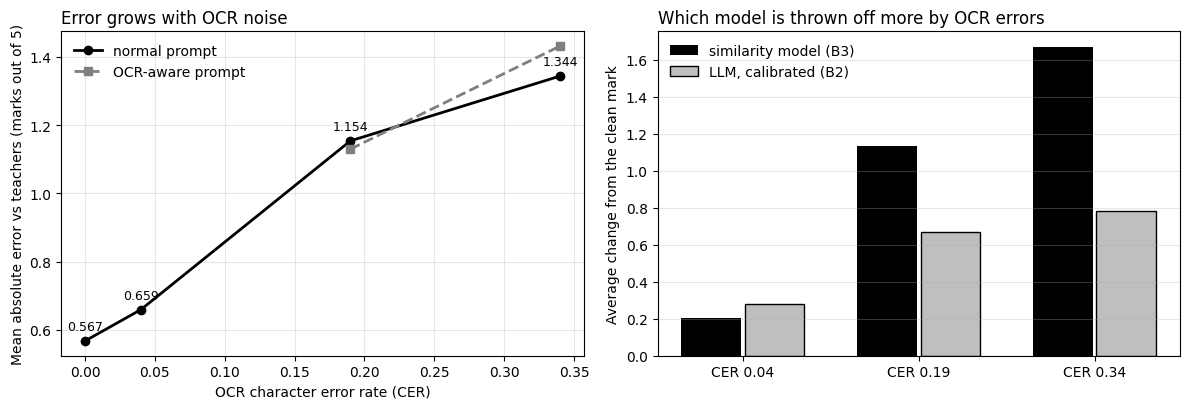

In [35]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plain = noise_summary[~noise_summary["condition"].str.contains("aware")]
aware = noise_summary[noise_summary["condition"].str.contains("aware")]
axes[0].plot(plain["measured CER"], plain["MAE vs teachers"], marker="o", color="#2a78d6", linewidth=2, label="normal prompt")
axes[0].plot(aware["measured CER"], aware["MAE vs teachers"], marker="s", color="#eb6834", linewidth=2, linestyle="--", label="OCR-aware prompt")
for i, row in plain.iterrows():
    axes[0].annotate(str(row["MAE vs teachers"]), (row["measured CER"], row["MAE vs teachers"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[0].set_xlabel("OCR character error rate (CER)")
axes[0].set_ylabel("Mean absolute error vs teachers (marks out of 5)")
axes[0].set_title("Error grows with OCR noise", loc="left")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.3)
labels = ["CER 0.04", "CER 0.19", "CER 0.34"]
positions = np.arange(len(labels))
similarity_changes = []
llm_changes = []
for label in labels:
    row = noise_summary[noise_summary["condition"] == label].iloc[0]
    similarity_changes.append(row["similarity model change"])
    llm_changes.append(row["LLM (calibrated) change"])
axes[1].bar(positions - 0.18, similarity_changes, 0.34, color="#2a78d6", label="similarity model (B3)")
axes[1].bar(positions + 0.18, llm_changes, 0.34, color="#eb6834", label="LLM, calibrated (B2)")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Average change from the clean mark")
axes[1].set_title("Which model is thrown off more by OCR errors", loc="left")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("results/week 7/week 7 ocr noise.png", dpi=170, bbox_inches="tight")
plt.show()

## 5. Long answers

Group 1's pages are much longer than Mohler answers. The similarity model reads at most 256 word-pieces (reference answer and student answer together), so on a long answer **it only sees the beginning**. The LLM reads the whole answer.

In [36]:
mohler_words = predictions["student_answer"].astype(str).str.split().str.len()
print("Mohler answers: mean", round(mohler_words.mean(), 1), "words | 95% have", int(mohler_words.quantile(0.95)), "or fewer | longest", int(mohler_words.max()))
print("Mohler answers over", grader.LONG_ANSWER_WORDS, "words:", int((mohler_words > grader.LONG_ANSWER_WORDS).sum()), "of", len(mohler_words))
reference = group1_answer_key["Q1"]["reference_answer"]
for name, style in page_names:
    answer_text = group1.pages_to_answers([group1_records[name]])[0]["answer_text"]
    pieces = len(grader.cross_tokenizer(reference, answer_text)["input_ids"])
    print(name, "|", len(answer_text.split()), "words | reference + answer =", pieces, "word-pieces, so the similarity model reads", round(100 * min(1, 256 / pieces)), "% of it")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (614 > 512). Running this sequence through the model will result in indexing errors


Mohler answers: mean 19.1 words | 95% have 45 or fewer | longest 174
Mohler answers over 100 words: 5 of 2264
aayush_page-01 | 139 words | reference + answer = 411 word-pieces, so the similarity model reads 62 % of it
rish_page-1 | 199 words | reference + answer = 614 word-pieces, so the similarity model reads 42 % of it


Week 7 therefore adds a **review rule**: an answer longer than 100 words is flagged ("Long answer: much longer than the answers the similarity model was trained on, so check the mark"). It affects only a handful of Mohler answers, but every full page from Group 1.

## 6. End-to-end test through the API

The complete chain a teacher would use: **scanned page → Group 1's digitizer (`POST /digitize`) → our adapter and grader (`POST /evaluate-group1-pages`)**. The teacher types the student ID, because the digitizer could not read it.

In [37]:
from fastapi.testclient import TestClient
import api

grader.cross_model = AutoModelForSequenceClassification.from_pretrained(grader.cross_encoder_folder)
grader.cross_model.eval()
grader.cross_tokenizer = AutoTokenizer.from_pretrained(grader.cross_encoder_folder)

client = TestClient(api.app)
print(client.get("/health").json())

api_examples = {}
for name, style in page_names:
    with open(group1_folder + "data/raw_scans/" + name + ".jpg", "rb") as file:
        digitized = client.post("/digitize", files={"image": (name + ".jpg", file, "image/jpeg")}, data={"page_number": "1"}).json()
    request_body = {"answer_key": group1_answer_key, "pages": [digitized], "student_id": ground_truth[name]["student_id"]}
    reply = client.post("/evaluate-group1-pages", json=request_body)
    body = reply.json()
    api_examples[name] = {"digitize_response": digitized, "evaluate_request": request_body, "evaluate_response": body}
    result = body["results"][0]
    print(name, "| status", reply.status_code, "| mark", result["score"], "/", result["maximum_score"], "| confidence", result["confidence"], "| pages", result["pages"])
    for reason in result["review_reasons"]:
        print("    review:", reason)
with open("results/week 7/week 7 api examples.json", "w") as file:
    json.dump(api_examples, file, indent=2)

Loading weights:   0%|          | 0/73 [00:00<?, ?it/s]

{'status': 'ok', 'similarity_model_loaded': True, 'llm_available': True, 'llm_provider': 'ollama', 'llm_model': 'qwen2.5:7b-instruct', 'group1_digitizer_available': True, 'version': 'week 7'}
aayush_page-01 | status 200 | mark 8.0 / 10.0 | confidence 0.86 | pages [1]
    review: Long answer (140 words): much longer than the answers the similarity model was trained on (95% had 45 words or fewer), so check the mark.
rish_page-1 | status 200 | mark 7.0 / 10.0 | confidence 0.53 | pages [1]
    review: Low OCR confidence (0.4): check the transcription against the answer sheet.
    review: Long answer (186 words): much longer than the answers the similarity model was trained on (95% had 45 words or fewer), so check the mark.
    review: Low confidence (0.53): the similarity model and the LLM disagree.
    review: The LLM score (4.5) and the rubric score (2.0) differ by 2 or more marks out of 5.


In [38]:
bad = client.post("/evaluate-group1-pages", json={"answer_key": group1_answer_key, "pages": [{"answer_text": "Q3) about routing", "page": 1, "ocr_confidence": 0.9}]})
print("Unknown question:", bad.status_code, bad.json())
missing = client.post("/evaluate-group1-pages", json={"answer_key": group1_answer_key, "pages": [{"page": 1}]})
print("Missing answer_text:", missing.status_code)

Unknown question: 200 {'results': [{'question': 'Q1', 'student_id': None, 'page': 1, 'pages': [1], 'answer_text': 'Q3) about routing', 'removed_header': '', 'score': 4.5, 'maximum_score': 10.0, 'feedback': 'Missing: An email passes down through the seven OSI layers at the sender (encapsulation) and back up at the receiver (de-encapsulation). Application layer: email programs use SMTP to send and IMAP or POP3 to receive emails. Presentation layer: formats, encodes, compresses and encrypts the message and attachments. Session layer: opens, manages and closes the session between the email client and the server. Transport layer: TCP splits the message into segments and delivers them reliably. Network layer: IP addresses and routes the packets between the mail servers. Data link and physical layers: frames and bits are sent over the physical network (cables or Wi-Fi). | Check this statement: about routing | The answer is off-topic and does not address the question about the OSI model and em

## 7. Updated architecture

The Week 6 diagram with the Week 7 additions: Group 1's digitizer at the input, the adapter in pre-processing, two new endpoints, and the React + Django teacher application.

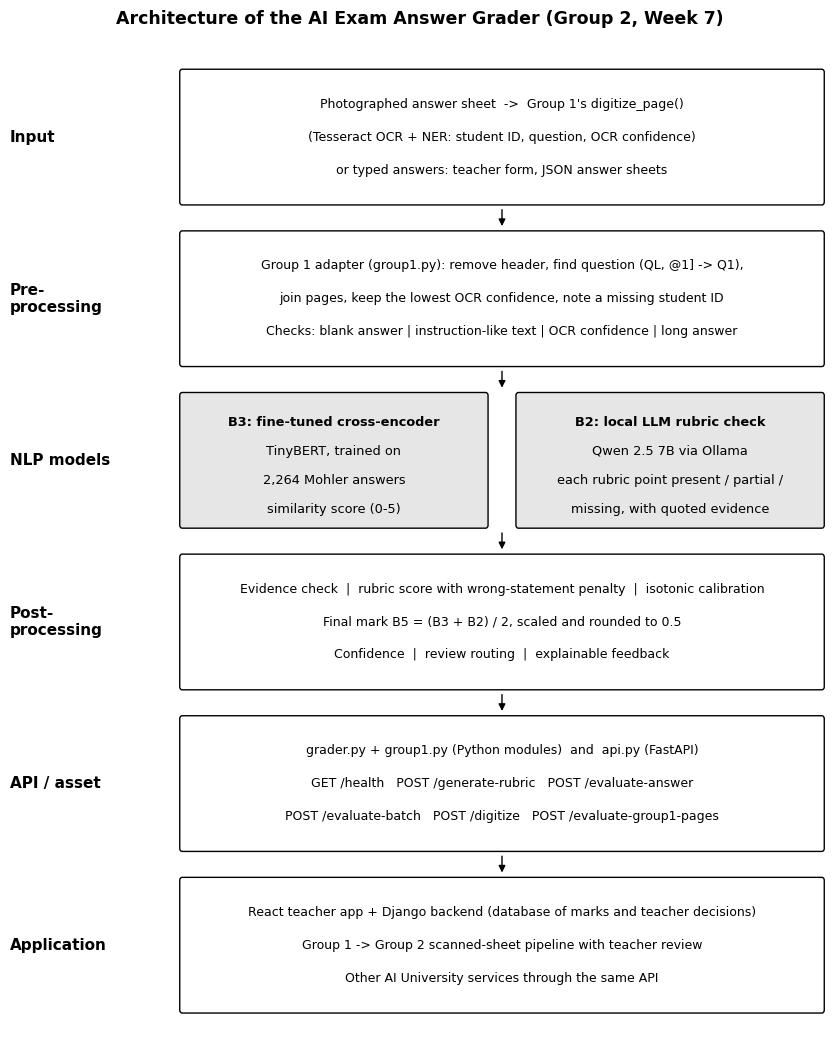

In [39]:
from matplotlib.patches import FancyBboxPatch

layers = [
    ("Input", ["Photographed answer sheet  ->  Group 1's digitize_page()", "(Tesseract OCR + NER: student ID, question, OCR confidence)", "or typed answers: teacher form, JSON answer sheets"]),
    ("Pre-\nprocessing", ["Group 1 adapter (group1.py): remove header, find question (QL, @1] -> Q1),", "join pages, keep the lowest OCR confidence, note a missing student ID", "Checks: blank answer | instruction-like text | OCR confidence | long answer"]),
    ("NLP models", []),
    ("Post-\nprocessing", ["Evidence check  |  rubric score with wrong-statement penalty  |  isotonic calibration", "Final mark B5 = (B3 + B2) / 2, scaled and rounded to 0.5", "Confidence  |  review routing  |  explainable feedback"]),
    ("API / asset", ["grader.py + group1.py (Python modules)  and  api.py (FastAPI)", "GET /health   POST /generate-rubric   POST /evaluate-answer", "POST /evaluate-batch   POST /digitize   POST /evaluate-group1-pages"]),
    ("Application", ["React teacher app + Django backend (database of marks and teacher decisions)", "Group 1 -> Group 2 scanned-sheet pipeline with teacher review", "Other AI University services through the same API"]),
]

figure, axis = plt.subplots(figsize=(8.5, 10.5))
axis.set_xlim(0, 100)
axis.set_ylim(0, 100)
axis.axis("off")
box_height = 13
gap = 3.2
top = 96
positions = []
for position in range(len(layers)):
    positions.append(top - position * (box_height + gap) - box_height)

for position in range(len(layers)):
    title, lines = layers[position]
    bottom = positions[position]
    axis.text(0, bottom + box_height / 2, title, fontsize=11, fontweight="bold", va="center", color="#1c5cab")
    if title == "NLP models":
        left_box = FancyBboxPatch((21, bottom), 37, box_height, boxstyle="round,pad=0.3", facecolor="#cde2fb", edgecolor="#2a78d6")
        right_box = FancyBboxPatch((62, bottom), 37, box_height, boxstyle="round,pad=0.3", facecolor="#fde3d8", edgecolor="#eb6834")
        axis.add_patch(left_box)
        axis.add_patch(right_box)
        left_lines = ["B3: fine-tuned cross-encoder", "TinyBERT, trained on", "2,264 Mohler answers", "similarity score (0-5)"]
        right_lines = ["B2: local LLM rubric check", "Qwen 2.5 7B via Ollama", "each rubric point present / partial /", "missing, with quoted evidence"]
        for number in range(4):
            weight = "normal"
            if number == 0:
                weight = "bold"
            axis.text(39.5, bottom + 10.3 - number * 2.9, left_lines[number], fontsize=9.3, ha="center", va="center", fontweight=weight)
            axis.text(80.5, bottom + 10.3 - number * 2.9, right_lines[number], fontsize=9.3, ha="center", va="center", fontweight=weight)
    else:
        box = FancyBboxPatch((21, bottom), 78, box_height, boxstyle="round,pad=0.3", facecolor="#f4f8fd", edgecolor="#2a78d6")
        axis.add_patch(box)
        for number in range(len(lines)):
            axis.text(60, bottom + 9.8 - number * 3.3, lines[number], fontsize=9, ha="center", va="center")
    if position < len(layers) - 1:
        axis.annotate("", xy=(60, positions[position + 1] + box_height + 0.5), xytext=(60, bottom - 0.5), arrowprops={"arrowstyle": "-|>", "color": "#2a78d6"})

axis.set_title("Architecture of the AI Exam Answer Grader (Group 2, Week 7)", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.savefig("results/week 7/week 7 architecture.png", dpi=170)
plt.show()

## 8. What we found

**Answer to ma'am's question.** The grader now accepts Group 1's output exactly as their digitizer returns it, and the full chain photo → Group 1 → our grader → teacher works through the API and the web app.

1. **Neat handwriting barely matters.** At Group 1's neat-page error rate (CER 0.04) the error against the teachers rises only from 0.567 to 0.659 marks and the marks move by 0.22 on average. On Group 1's real neat page the mark was identical from the true text and from the OCR text (8 / 10).
2. **Messy handwriting matters a lot.** At CER 0.19 the error doubles (1.154) and at CER 0.34 (cursive) it is 1.344; within ±1 mark falls from 76% to 47% and 34%. Both drops are significant (bootstrap over questions).
3. **The similarity model is hurt most.** Its score moves by 1.13 and 1.67 marks at CER 0.19 and 0.34, against 0.67 and 0.78 for the LLM: character errors break word matching, while the LLM still reads the words the student meant.
4. **Our own review rules catch only part of it** (38–39% of noisy answers flagged, against 23% of clean ones). So **Group 1's OCR confidence must be used**: it was 0.82 on the neat page and 0.40 on the cursive page, and every answer below 0.80 goes to a teacher, who can correct the transcription in the web app before grading.
5. **The OCR-aware prompt did not help** (+0.024 marks at CER 0.19, −0.088 at 0.34, neither significant). It is kept as an option (`from_ocr=True`) but is **off by default**.
6. **Long answers and a different course.** Group 1's pages are 140–190 words and the similarity model reads only about the first half; such answers are now flagged. Both real pages got about 8 / 10 although page 1 covers at most 3 of the 7 rubric points: the calibration learned from the lenient Mohler teachers does not transfer to a new course. A few teacher-marked answers from the new course would be needed to recalibrate.

These are measured on 95 answers with simulated OCR errors and on only two real pages, so they show the size of the effects rather than exact rates.